# Ortaöğretim Öğrencilerinde Akademik Başarıyı Etkileyen Faktörler
**Araştırma Yöntem ve Teknikleri – Dönem Projesi (Vize aşaması)**

**Araştırma sorusu:** Ortaöğretim öğrencilerinde haftalık çalışma süresi, geçmiş ders başarısızlığı, devamsızlık ve aile/sosyal etkenler ile dönem sonu notu (G3) arasında ilişki var mıdır; bu değişkenler öğrencinin dersi geçip geçmeyeceğini önceden tahmin etmeye yeterli midir?

**Hipotezler**
- **H1:** Haftalık çalışma süresi (`studytime`) ile dönem sonu notu (G3) arasında pozitif yönlü ilişki vardır.
- **H2:** Geçmiş ders başarısızlığı sayısı (`failures`) ile G3 arasında negatif yönlü ilişki vardır.
- **H3:** Devamsızlık sayısı (`absences`) ile G3 arasında negatif yönlü ilişki vardır.
- **H0 (her biri için):** İlgili değişken ile G3 arasında ilişki yoktur.

**Veri:** UCI Machine Learning Repository – *Student Performance* (Cortez, 2008), https://archive.ics.uci.edu/dataset/320/student+performance — Lisans: CC BY 4.0.
Bu projede kişilerden doğrudan veri toplanmamıştır; yalnızca açık erişimli ikincil veri kullanılmıştır.

## 1. Kütüphaneler

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

RASTGELE = 42                      # tekrarlanabilirlik için sabit tohum
np.random.seed(RASTGELE)
sns.set_theme(style="whitegrid")
os.makedirs("sekiller", exist_ok=True)
print("Hazır.")

Hazır.


## 2. Verinin yüklenmesi
Veri, UCI deposundaki resmî zip dosyasından indirilir. `veri/` klasöründe CSV dosyaları varsa (ör. GitHub deposu klonlandıysa) onlar kullanılır.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

def zipten_csv_cikar(zip_bytes, hedef):
    # UCI zip dosyası iç içe zip içerebilir; tüm CSV'leri bulur.
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
        for ad in z.namelist():
            if ad.endswith(".zip"):
                zipten_csv_cikar(z.read(ad), hedef)
            elif ad.endswith(".csv"):
                hedef[os.path.basename(ad)] = z.read(ad)

def veri_yukle():
    if os.path.exists("veri/student-mat.csv") and os.path.exists("veri/student-por.csv"):
        print("Yerel dosyalar kullanılıyor: veri/")
        return (pd.read_csv("veri/student-mat.csv", sep=";"),
                pd.read_csv("veri/student-por.csv", sep=";"))
    print("UCI deposundan indiriliyor...")
    zb = urllib.request.urlopen(UCI_URL, timeout=60).read()
    csvler = {}
    zipten_csv_cikar(zb, csvler)
    return (pd.read_csv(io.BytesIO(csvler["student-mat.csv"]), sep=";"),
            pd.read_csv(io.BytesIO(csvler["student-por.csv"]), sep=";"))

mat, por = veri_yukle()
print("Matematik dersi :", mat.shape)
print("Portekizce dersi:", por.shape)
mat.head()

Yerel dosyalar kullanılıyor: veri/
Matematik dersi : (395, 33)
Portekizce dersi: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 3. Veri setinin tanınması
Her satır bir öğrenciyi (gözlem), her sütun bir değişkeni gösterir. Eksik değer kontrolü ve temel değişkenlerin anlamları:

| Değişken | Açıklama | Tür / birim |
|---|---|---|
| `studytime` | Haftalık ders çalışma süresi (1: <2 sa, 2: 2–5 sa, 3: 5–10 sa, 4: >10 sa) | Sıralı (1–4) |
| `failures` | Geçmişte başarısız olunan ders sayısı (4 = 4 ve üzeri) | Sayısal (0–4) |
| `absences` | Okul devamsızlık sayısı | Sayısal (0–93) |
| `Medu`, `Fedu` | Anne / baba eğitim düzeyi (0: yok … 4: yükseköğretim) | Sıralı (0–4) |
| `higher` | Yükseköğretime devam etmek istiyor mu? | Kategorik (yes/no) |
| `goout` | Arkadaşlarla dışarı çıkma sıklığı | Sıralı (1–5) |
| `Dalc`, `Walc` | Hafta içi / hafta sonu alkol tüketimi | Sıralı (1–5) |
| `G1`, `G2` | 1. ve 2. dönem notu | Sayısal (0–20) |
| `G3` | **Dönem sonu notu (bağımlı değişken)** | Sayısal (0–20) |

In [3]:
print("Eksik değer sayısı (mat):", int(mat.isna().sum().sum()))
print("Eksik değer sayısı (por):", int(por.isna().sum().sum()))
print("\nDeğişken türleri:")
print(mat.dtypes.value_counts())

Eksik değer sayısı (mat): 0
Eksik değer sayısı (por): 0

Değişken türleri:
str      17
int64    16
Name: count, dtype: int64


## 4. Betimsel istatistikler (Matematik dersi)

In [4]:
df = mat.copy()
df["gecti"] = (df["G3"] >= 10).astype(int)       # Portekiz sisteminde geçme notu 10/20

secili = ["age", "studytime", "failures", "absences", "Medu", "Fedu", "goout", "G1", "G2", "G3"]
betimsel = df[secili].describe().T[["mean", "std", "min", "50%", "max"]].round(2)
betimsel.columns = ["Ortalama", "Std. sapma", "Min", "Medyan", "Maks"]
display(betimsel)

print(f"Dersi geçen öğrenci oranı: %{100*df['gecti'].mean():.1f}  (n={len(df)})")
print(f"G3 = 0 olan öğrenci sayısı: {(df['G3']==0).sum()}  (sınava girmeyen/terk eden öğrenciler olabilir)")

,Ortalama,Std. sapma,Min,Medyan,Maks
age,16.70,1.28,15.0,17.0,22.0
studytime,2.04,0.84,1.0,2.0,4.0
failures,0.33,0.74,0.0,0.0,3.0
absences,5.71,8.00,0.0,4.0,75.0
Medu,2.75,1.09,0.0,3.0,4.0
Fedu,2.52,1.09,0.0,2.0,4.0
goout,3.11,1.11,1.0,3.0,5.0
G1,10.91,3.32,3.0,11.0,19.0
G2,10.71,3.76,0.0,11.0,19.0
G3,10.42,4.58,0.0,11.0,20.0


Dersi geçen öğrenci oranı: %67.1  (n=395)
G3 = 0 olan öğrenci sayısı: 38  (sınava girmeyen/terk eden öğrenciler olabilir)


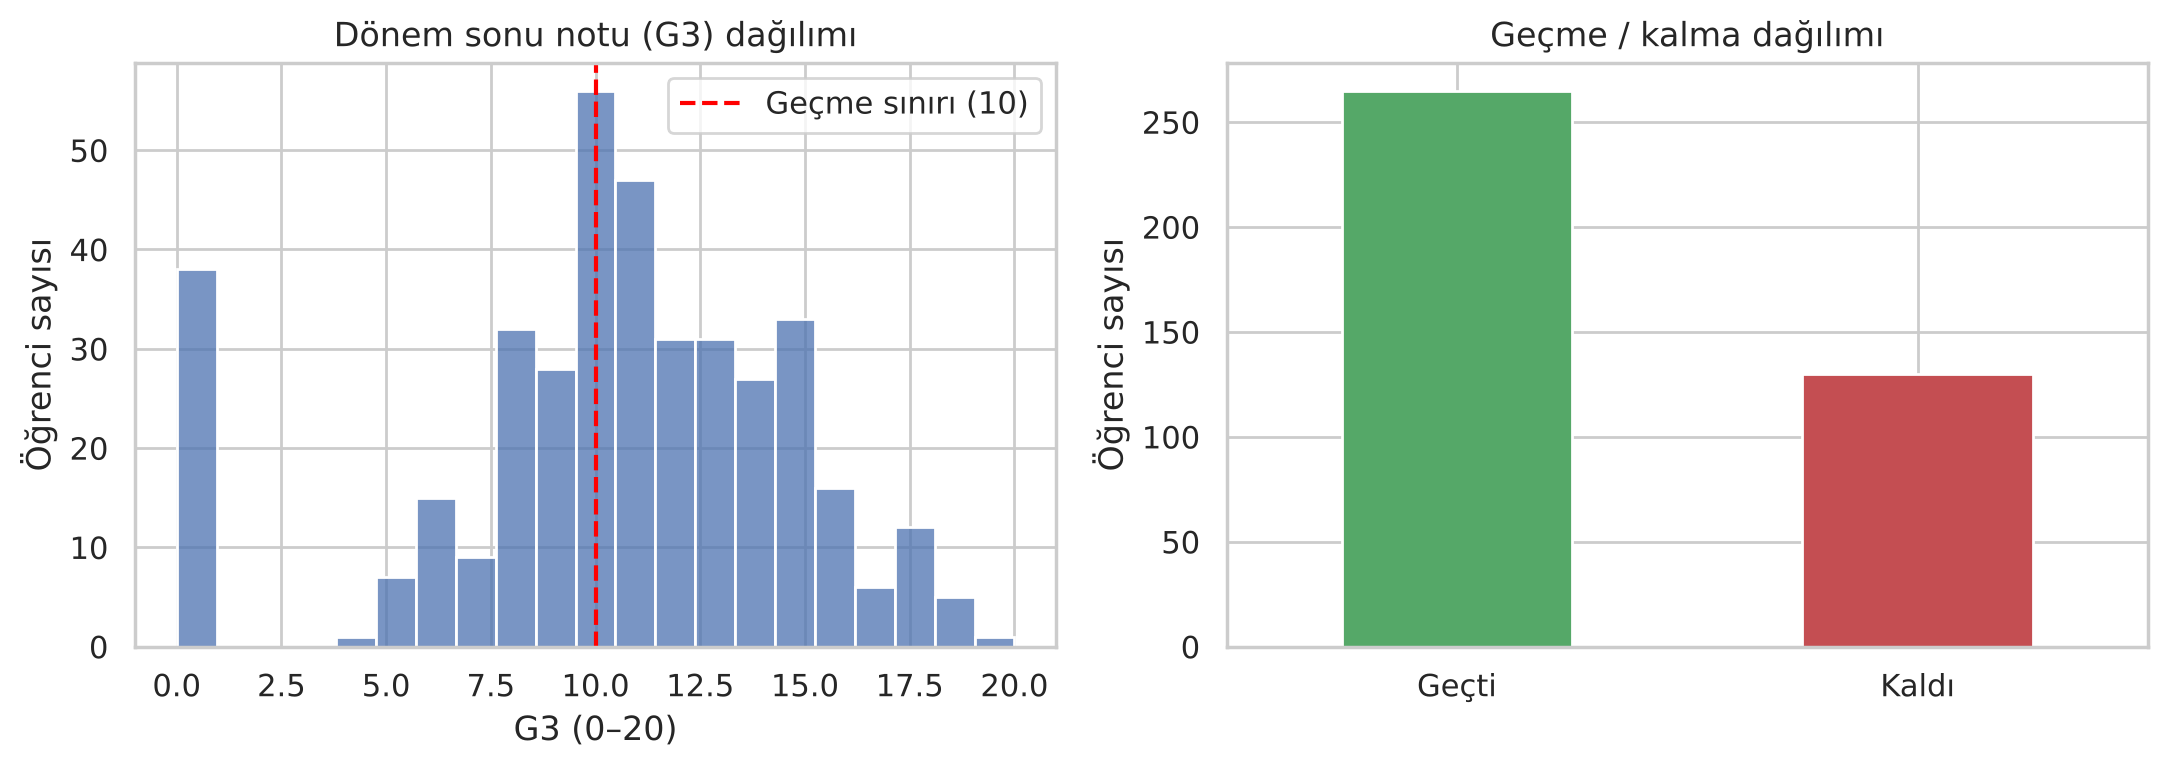

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["G3"], bins=21, ax=ax[0], color="#4C72B0")
ax[0].axvline(10, color="red", ls="--", label="Geçme sınırı (10)")
ax[0].set(title="Dönem sonu notu (G3) dağılımı", xlabel="G3 (0–20)", ylabel="Öğrenci sayısı")
ax[0].legend()
df["gecti"].map({1: "Geçti", 0: "Kaldı"}).value_counts().plot.bar(ax=ax[1], color=["#55A868", "#C44E52"])
ax[1].set(title="Geçme / kalma dağılımı", xlabel="", ylabel="Öğrenci sayısı")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("sekiller/01_g3_dagilimi.png", dpi=150); plt.show()

## 5. Hipotez testleri: Spearman sıra korelasyonu
Değişkenlerin çoğu sıralı ölçekte olduğu ve G3 normal dağılmadığı için parametrik olmayan **Spearman korelasyonu** kullanılmıştır. Anlamlılık düzeyi α = 0,05.

In [6]:
def spearman_tablosu(veri, degiskenler, hedef="G3"):
    satirlar = []
    for d in degiskenler:
        rho, p = stats.spearmanr(veri[d], veri[hedef])
        satirlar.append({"Değişken": d, "rho": round(rho, 3), "p": p,
                         "Anlamlı (p<0,05)": "Evet" if p < 0.05 else "Hayır"})
    t = pd.DataFrame(satirlar).sort_values("rho", key=abs, ascending=False)
    t["p"] = t["p"].map(lambda x: f"{x:.4f}" if x >= 0.0001 else "<0,0001")
    return t.reset_index(drop=True)

aday = ["failures", "studytime", "absences", "Medu", "Fedu", "goout", "age",
        "Dalc", "Walc", "health", "freetime", "famrel", "traveltime"]
kor_mat = spearman_tablosu(df, aday)
display(kor_mat)

,Değişken,rho,p,"Anlamlı (p<0,05)"
0,failures,-0.361,"<0,0001",Evet
1,Medu,0.225,"<0,0001",Evet
2,age,-0.173,0.0005,Evet
3,Fedu,0.170,0.0007,Evet
4,goout,-0.166,0.0009,Evet
5,Dalc,-0.121,0.0162,Evet
6,traveltime,-0.121,0.0165,Evet
7,studytime,0.105,0.0367,Evet
8,Walc,-0.104,0.0380,Evet
9,famrel,0.055,0.2757,Hayır


In [7]:
# Hipotezlerin karar özeti
for h, d, beklenen in [("H1", "studytime", "+"), ("H2", "failures", "-"), ("H3", "absences", "-")]:
    rho, p = stats.spearmanr(df[d], df["G3"])
    yon_ok = (rho > 0) if beklenen == "+" else (rho < 0)
    karar = "DESTEKLENDİ" if (p < 0.05 and yon_ok) else "DESTEKLENMEDİ"
    print(f"{h} ({d}): rho={rho:+.3f}, p={p:.4f} -> {karar}")

H1 (studytime): rho=+0.105, p=0.0367 -> DESTEKLENDİ
H2 (failures): rho=-0.361, p=0.0000 -> DESTEKLENDİ
H3 (absences): rho=+0.018, p=0.7254 -> DESTEKLENMEDİ


### Sağlamlık kontrolü: G3 = 0 olan öğrenciler
G3 = 0 olan öğrencilerin tamamının devamsızlık sayısı 0'dır. Bu öğrenciler büyük olasılıkla dönem sonu sınavına girmemiş ya da okulu bırakmıştır; devamsızlık kayıtları da bu nedenle eksik kalmış olabilir. Analiz bu öğrenciler çıkarılarak tekrarlanır.

In [8]:
print("G3 = 0 olanlarda ortalama devamsızlık:", round(df.loc[df.G3 == 0, "absences"].mean(), 2))
print("Diğer öğrencilerde ortalama devamsızlık:", round(df.loc[df.G3 > 0, "absences"].mean(), 2))
df_nz = df[df["G3"] > 0]
print(f"\nG3 > 0 olan öğrenciler (n={len(df_nz)}):")
for h, d in [("H1", "studytime"), ("H2", "failures"), ("H3", "absences")]:
    rho, p = stats.spearmanr(df_nz[d], df_nz["G3"])
    print(f"  {h} ({d}): rho={rho:+.3f}, p={p:.4f}")

G3 = 0 olanlarda ortalama devamsızlık: 0.0
Diğer öğrencilerde ortalama devamsızlık: 6.32

G3 > 0 olan öğrenciler (n=357):
  H1 (studytime): rho=+0.110, p=0.0380
  H2 (failures): rho=-0.299, p=0.0000
  H3 (absences): rho=-0.244, p=0.0000


### Kategorik değişkenler: Mann–Whitney U testi

In [9]:
satirlar = []
for d in ["higher", "internet", "schoolsup", "paid", "romantic", "sex", "address"]:
    gruplar = df.groupby(d)["G3"]
    seviyeler = list(gruplar.groups.keys())
    a, b = [df.loc[df[d] == s, "G3"] for s in seviyeler]
    u, p = stats.mannwhitneyu(a, b)
    satirlar.append({"Değişken": d,
                     "Gruplar (medyan G3)": ", ".join(f"{s}: {df.loc[df[d]==s,'G3'].median():.0f} (n={len(df.loc[df[d]==s])})" for s in seviyeler),
                     "p": round(p, 4), "Anlamlı": "Evet" if p < 0.05 else "Hayır"})
display(pd.DataFrame(satirlar))

,Değişken,Gruplar (medyan G3),p,Anlamlı
0,higher,"no: 8 (n=20), yes: 11 (n=375)",0.0006,Evet
1,internet,"no: 10 (n=66), yes: 11 (n=329)",0.0324,Evet
2,schoolsup,"no: 11 (n=344), yes: 10 (n=51)",0.0028,Evet
3,paid,"no: 11 (n=214), yes: 11 (n=181)",0.2267,Hayır
4,romantic,"no: 11 (n=263), yes: 11 (n=132)",0.0695,Hayır
5,sex,"F: 10 (n=208), M: 11 (n=187)",0.0407,Evet
6,address,"R: 10 (n=88), U: 11 (n=307)",0.0178,Evet


## 6. Görselleştirme

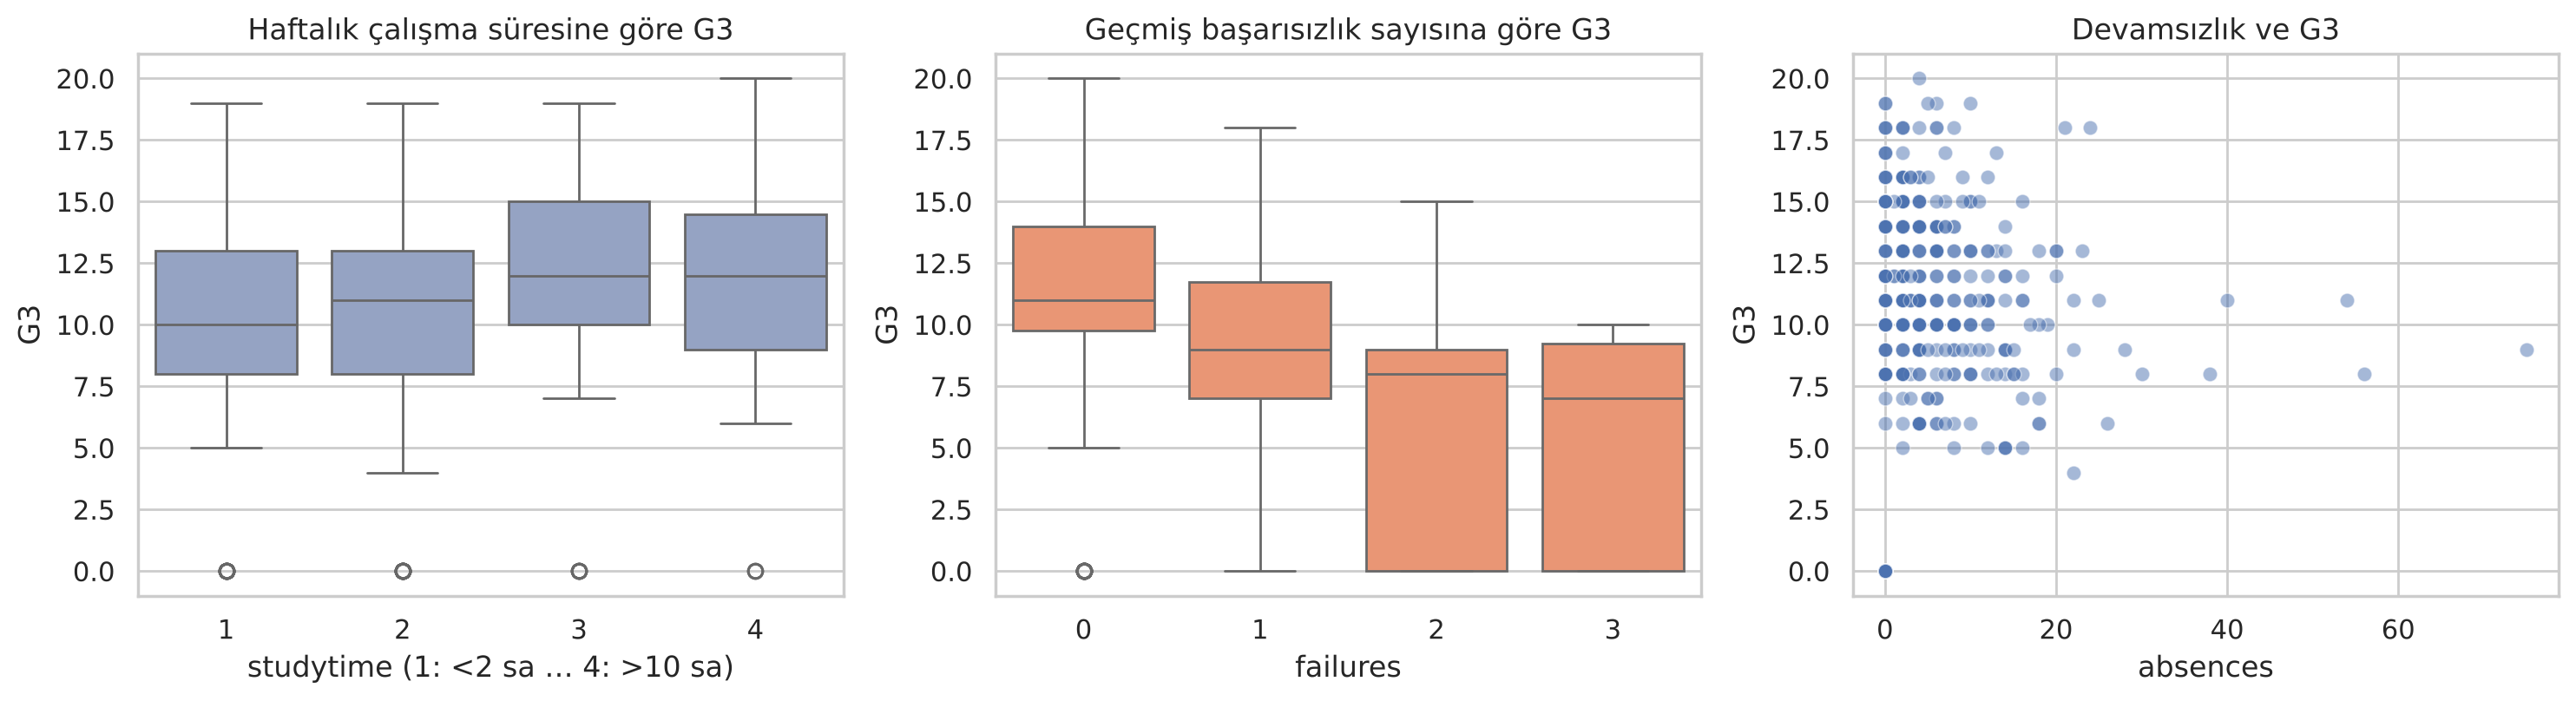

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.boxplot(data=df, x="studytime", y="G3", ax=ax[0], color="#8DA0CB")
ax[0].set(title="Haftalık çalışma süresine göre G3", xlabel="studytime (1: <2 sa … 4: >10 sa)")
sns.boxplot(data=df, x="failures", y="G3", ax=ax[1], color="#FC8D62")
ax[1].set(title="Geçmiş başarısızlık sayısına göre G3", xlabel="failures")
sns.scatterplot(data=df, x="absences", y="G3", ax=ax[2], alpha=0.5)
ax[2].set(title="Devamsızlık ve G3", xlabel="absences")
plt.tight_layout(); plt.savefig("sekiller/02_hipotez_grafikleri.png", dpi=150); plt.show()

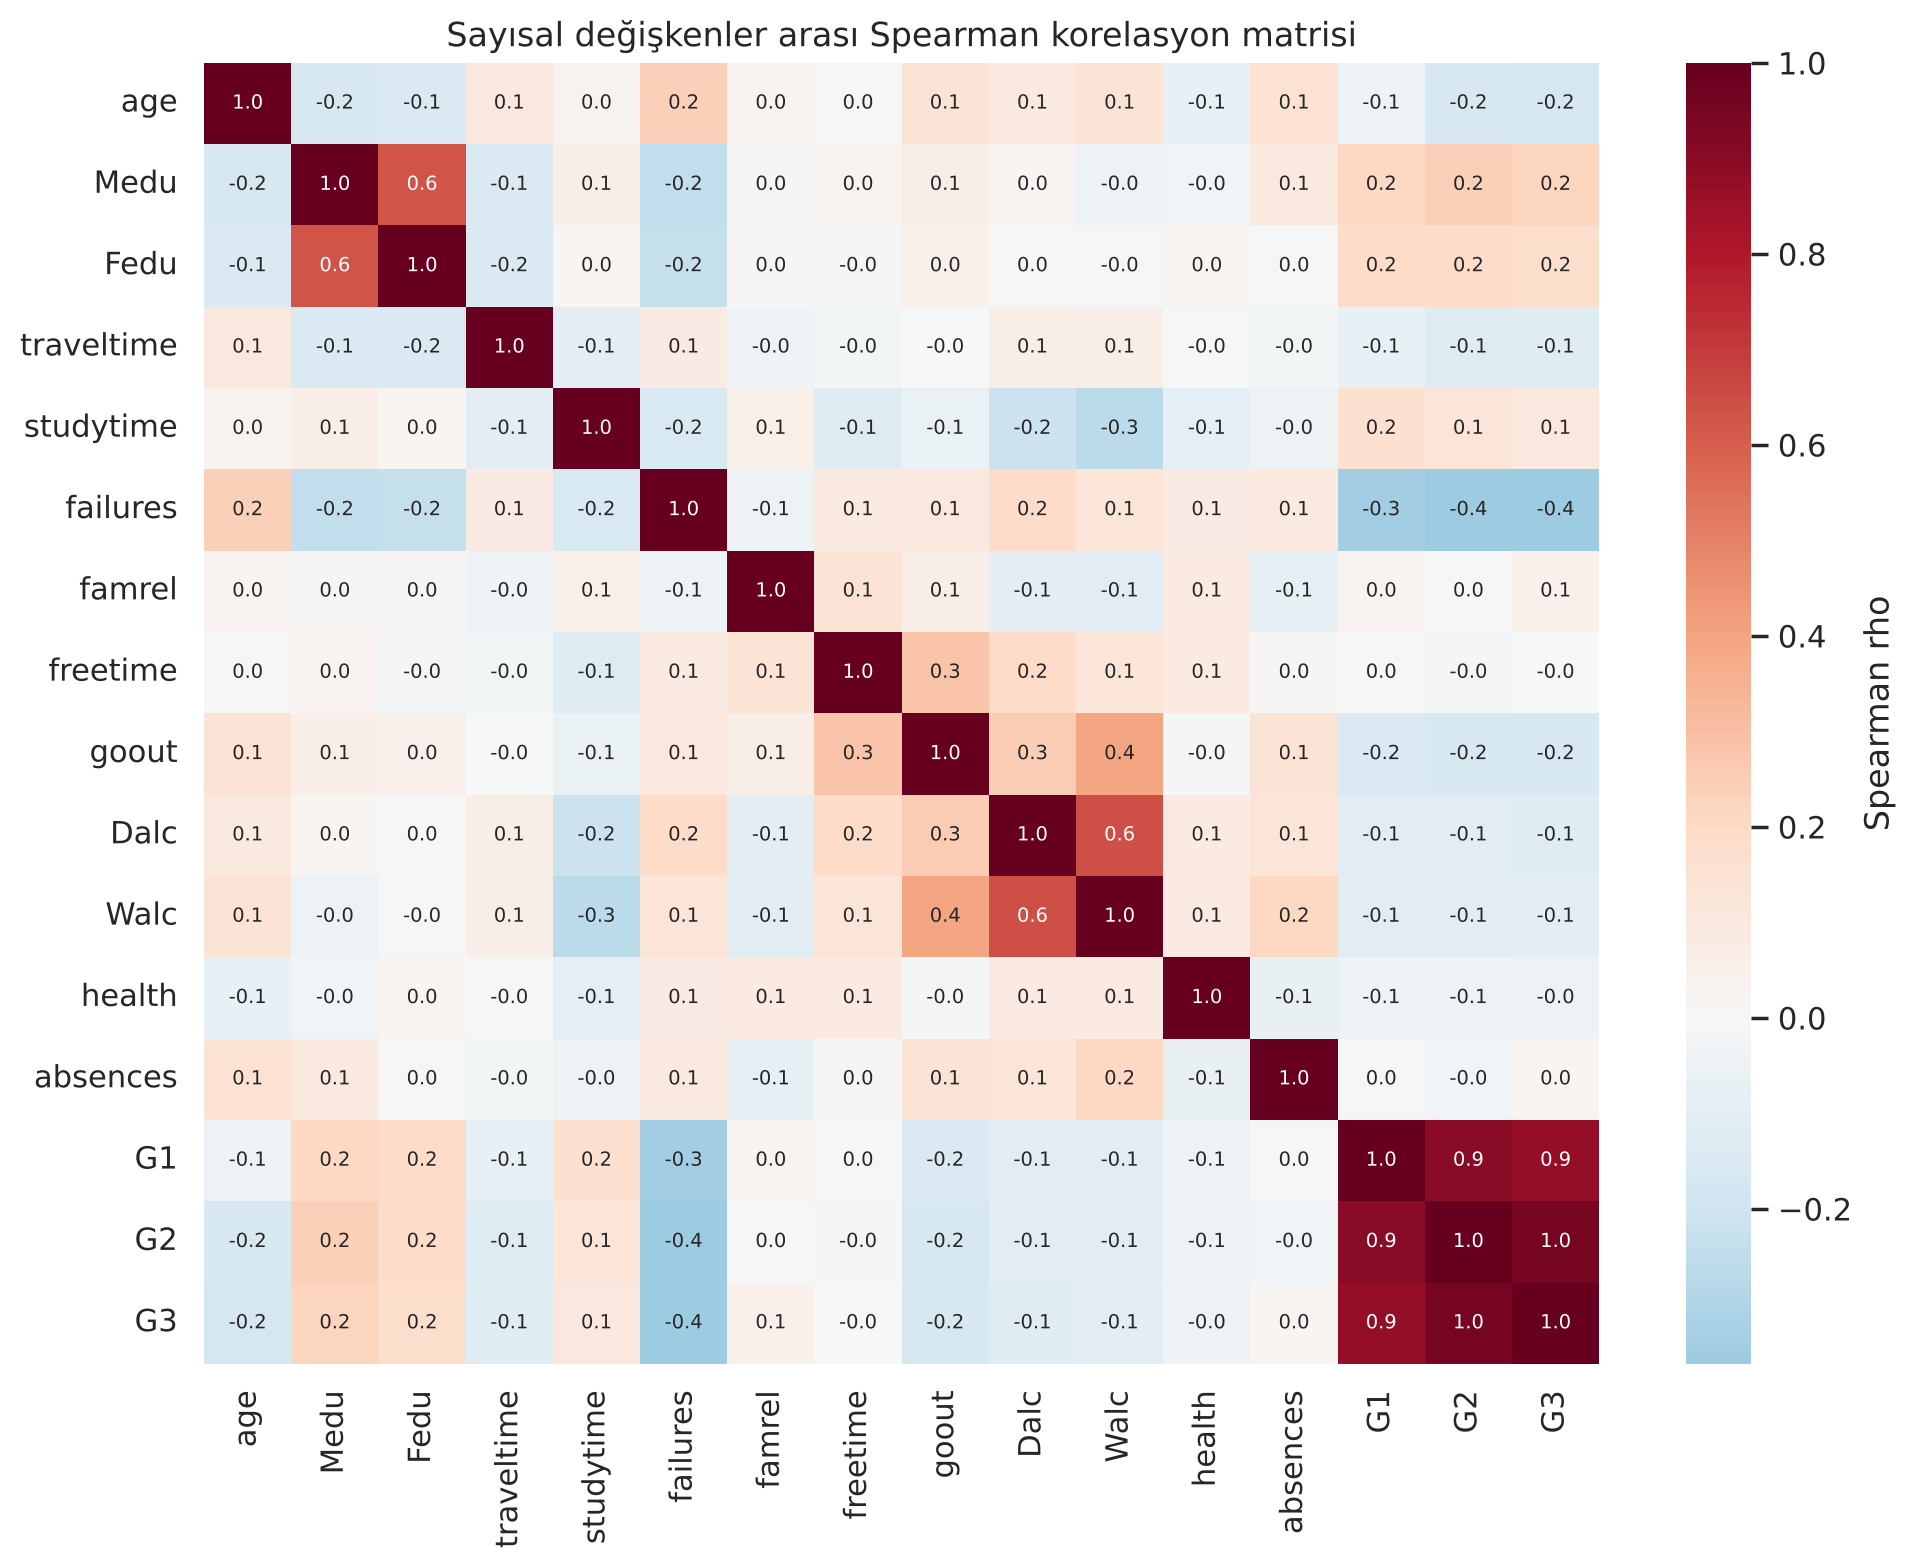

In [11]:
sayisal = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures", "famrel", "freetime",
           "goout", "Dalc", "Walc", "health", "absences", "G1", "G2", "G3"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[sayisal].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, cbar_kws={"label": "Spearman rho"})
plt.title("Sayısal değişkenler arası Spearman korelasyon matrisi")
plt.tight_layout(); plt.savefig("sekiller/03_korelasyon_matrisi.png", dpi=150); plt.show()

## 7. Geçme/kalma tahmini (ikili sınıflandırma)
Hedef: `gecti` (G3 ≥ 10). İki senaryo karşılaştırılır (Cortez ve Silva, 2008'deki kurguya benzer):
- **Senaryo A:** Önceki dönem notları (G1, G2) **dahil**.
- **Senaryo B:** G1 ve G2 **hariç** — yalnızca demografik, sosyal ve okulla ilgili değişkenler. Erken uyarı için daha yararlı ama daha zor.

Modeller: çoğunluk sınıfı (temel model), lojistik regresyon, karar ağacı, rastgele orman. Değerlendirme: 10 katlı tabakalı çapraz doğrulama; doğruluk (accuracy) ve makro F1. Ön işleme adımları her katta yalnızca eğitim verisiyle öğrenilir (veri sızıntısını önlemek için `Pipeline`).

In [12]:
def ozellik_hedef(veri, notlar_dahil):
    X = veri.drop(columns=["G3"] + ([] if notlar_dahil else ["G1", "G2"]))
    y = (veri["G3"] >= 10).astype(int)
    return X, y

def on_isleme(X):
    kat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    say = [c for c in X.columns if c not in kat]
    return ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore"), kat),
                              ("say", StandardScaler(), say)])

MODELLER = {
    "Çoğunluk sınıfı (temel)": DummyClassifier(strategy="most_frequent"),
    "Lojistik regresyon": LogisticRegression(max_iter=2000),
    "Karar ağacı (derinlik 4)": DecisionTreeClassifier(max_depth=4, random_state=RASTGELE),
    "Rastgele orman": RandomForestClassifier(n_estimators=300, random_state=RASTGELE),
}

def degerlendir(veri, ders_adi):
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RASTGELE)
    satirlar = []
    for senaryo, dahil in [("A: G1, G2 dahil", True), ("B: G1, G2 hariç", False)]:
        X, y = ozellik_hedef(veri, dahil)
        for ad, model in MODELLER.items():
            boru = Pipeline([("on", on_isleme(X)), ("model", model)])
            s = cross_validate(boru, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
            satirlar.append({"Ders": ders_adi, "Senaryo": senaryo, "Model": ad,
                             "Doğruluk": f"{s['test_accuracy'].mean():.3f} ± {s['test_accuracy'].std():.3f}",
                             "Makro F1": f"{s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}"})
    return pd.DataFrame(satirlar)

sonuc_mat = degerlendir(mat, "Matematik")
display(sonuc_mat)

,Ders,Senaryo,Model,Doğruluk,Makro F1
0,Matematik,"A: G1, G2 dahil",Çoğunluk sınıfı (temel),0.671 ± 0.004,0.401 ± 0.001
1,Matematik,"A: G1, G2 dahil",Lojistik regresyon,0.929 ± 0.040,0.919 ± 0.047
2,Matematik,"A: G1, G2 dahil",Karar ağacı (derinlik 4),0.891 ± 0.040,0.876 ± 0.045
3,Matematik,"A: G1, G2 dahil",Rastgele orman,0.909 ± 0.043,0.895 ± 0.053
4,Matematik,"B: G1, G2 hariç",Çoğunluk sınıfı (temel),0.671 ± 0.004,0.401 ± 0.001
5,Matematik,"B: G1, G2 hariç",Lojistik regresyon,0.673 ± 0.081,0.588 ± 0.092
6,Matematik,"B: G1, G2 hariç",Karar ağacı (derinlik 4),0.694 ± 0.053,0.615 ± 0.059
7,Matematik,"B: G1, G2 hariç",Rastgele orman,0.694 ± 0.028,0.568 ± 0.054


In [13]:
# Aynı deney Portekizce dersi verisinde (n=649) tekrarlanır
sonuc_por = degerlendir(por, "Portekizce")
display(sonuc_por)
pd.concat([sonuc_mat, sonuc_por]).to_csv("sonuclar_model.csv", index=False)

,Ders,Senaryo,Model,Doğruluk,Makro F1
0,Portekizce,"A: G1, G2 dahil",Çoğunluk sınıfı (temel),0.846 ± 0.001,0.458 ± 0.000
1,Portekizce,"A: G1, G2 dahil",Lojistik regresyon,0.929 ± 0.022,0.857 ± 0.046
2,Portekizce,"A: G1, G2 dahil",Karar ağacı (derinlik 4),0.921 ± 0.017,0.839 ± 0.046
3,Portekizce,"A: G1, G2 dahil",Rastgele orman,0.920 ± 0.015,0.822 ± 0.050
4,Portekizce,"B: G1, G2 hariç",Çoğunluk sınıfı (temel),0.846 ± 0.001,0.458 ± 0.000
5,Portekizce,"B: G1, G2 hariç",Lojistik regresyon,0.849 ± 0.027,0.634 ± 0.083
6,Portekizce,"B: G1, G2 hariç",Karar ağacı (derinlik 4),0.838 ± 0.029,0.644 ± 0.099
7,Portekizce,"B: G1, G2 hariç",Rastgele orman,0.851 ± 0.020,0.568 ± 0.088


## 8. Hangi değişkenler daha önemli? (Senaryo B, permütasyon önemi)
Senaryo B'de (G1, G2 hariç) rastgele orman modeli 10 katlı çapraz doğrulamanın her katında eğitilir; test katında her değişken rastgele karıştırıldığında **dengeli doğruluktaki (balanced accuracy)** düşüş ölçülür ve katlar boyunca ortalaması alınır. Sınıflar dengesiz olduğu için modele `class_weight="balanced"` verilmiştir.

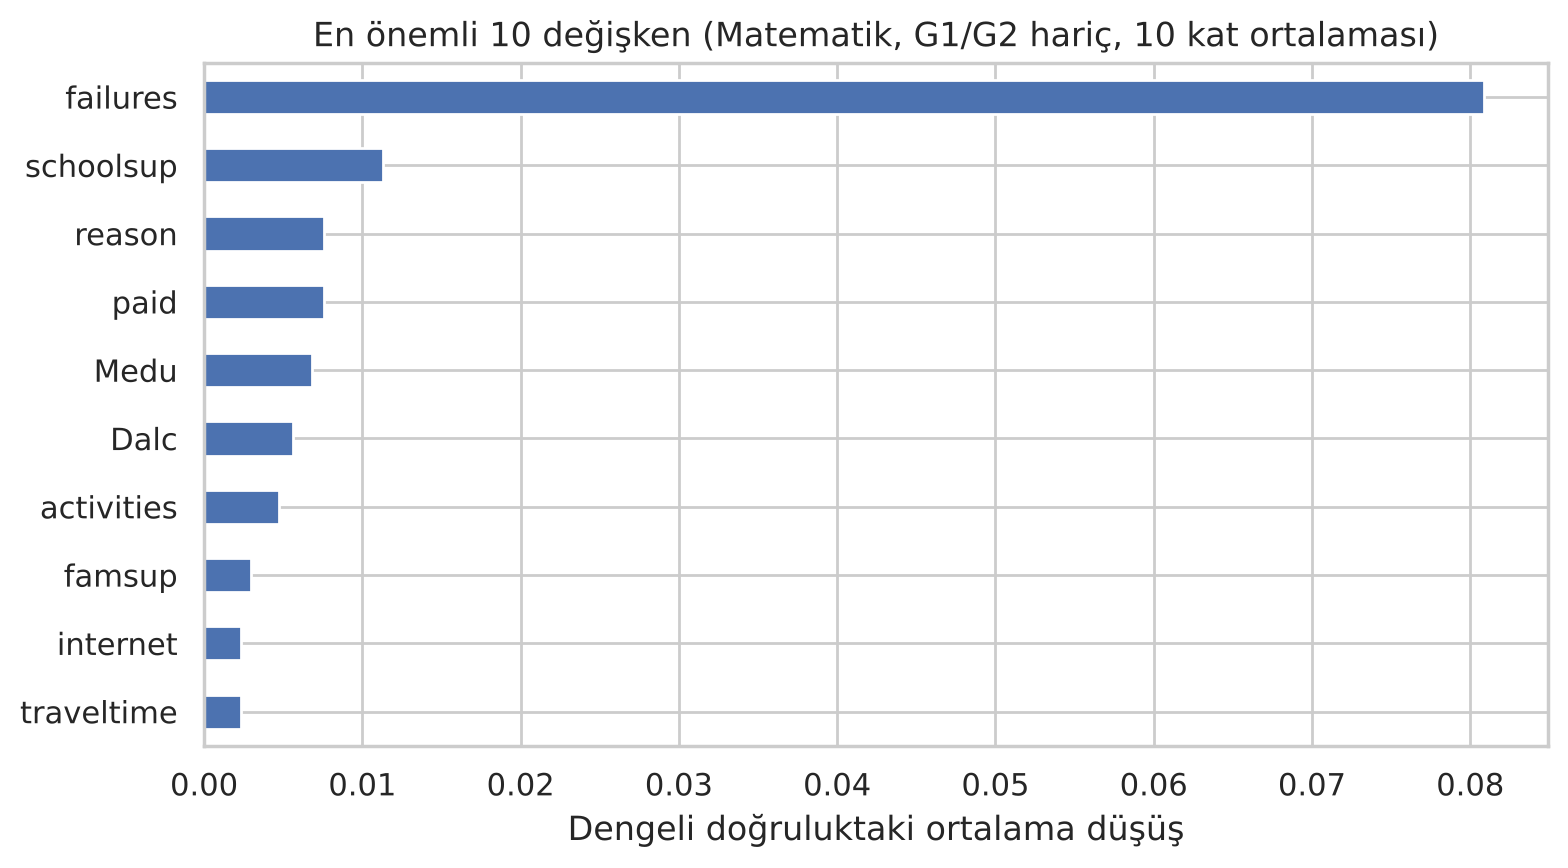

failures      0.0809
schoolsup     0.0113
reason        0.0076
paid          0.0075
Medu          0.0068
Dalc          0.0056
activities    0.0047
famsup        0.0030
internet      0.0024
traveltime    0.0023
dtype: float64

In [14]:
X, y = ozellik_hedef(mat, notlar_dahil=False)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RASTGELE)
onemler = []
for egitim, test in cv.split(X, y):
    boru = Pipeline([("on", on_isleme(X)),
                     ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RASTGELE))])
    boru.fit(X.iloc[egitim], y.iloc[egitim])
    pi = permutation_importance(boru, X.iloc[test], y.iloc[test], n_repeats=10,
                                random_state=RASTGELE, scoring="balanced_accuracy")
    onemler.append(pi.importances_mean)
onem = pd.Series(np.mean(onemler, axis=0), index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4.5))
onem[::-1].plot.barh(color="#4C72B0")
plt.title("En önemli 10 değişken (Matematik, G1/G2 hariç, 10 kat ortalaması)")
plt.xlabel("Dengeli doğruluktaki ortalama düşüş")
plt.tight_layout(); plt.savefig("sekiller/04_degisken_onemi.png", dpi=150); plt.show()
onem.round(4)

## 9. Bu aşamadaki sonuçlar ve sonraki adımlar
- Sonuçların yorumu raporun *Gerçekleştirilen Çalışmalar* bölümünde yer almaktadır.
- **Sınırlılıklar:** Veri iki Portekiz okulundaki öğrencilerden 2005–2006 döneminde toplanmıştır; Türkiye bağlamına genellenemez. Değişkenlerin bir kısmı öz bildirime dayalıdır. Korelasyon nedensellik göstermez.
- **Sonraki adımlar (finale kadar):** hiperparametre ayarı, sınıf dengesizliğine yönelik yöntemler, regresyon (G3'ün sayısal tahmini), iki dersin birleştirilmiş analizi, bulguların literatürle karşılaştırılması.